# Boston Housing Regression Lab

## Imports

In [51]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge, SGDRegressor
from sklearn.metrics import ( mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

## Load DataSet

In [52]:
housing_df = pd.read_csv("../data/boston_housing.csv")

display(housing_df.head())
display(housing_df.tail())

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0
505,0.04741,0.0,11.93,0,0.573,6.030,80.8,2.5050,1,273,21.0,7.88,11.9


# Examine dataset

In [53]:
print(housing_df.isnull().sum())
housing_df.info()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      0
MEDV       0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  LSTAT    506 non-null    float64
 12  MEDV     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


# EDA

Histogram of MEDV feature

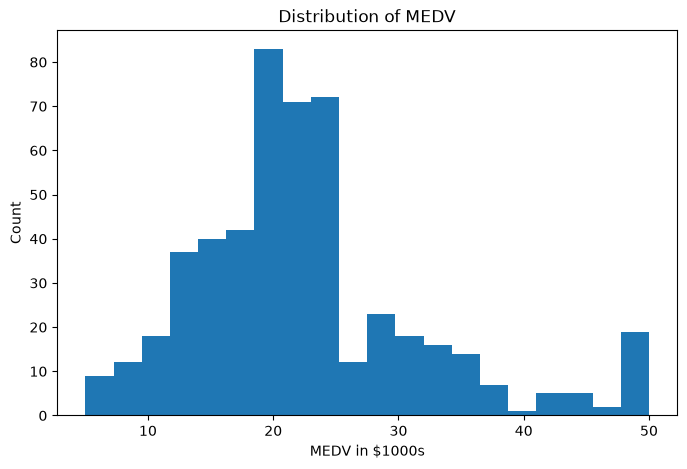

In [54]:
plt.figure(figsize=(8,5))
plt.hist(housing_df["MEDV"], bins=20)

plt.title("Distribution of MEDV")
plt.xlabel("MEDV in $1000s")
plt.ylabel("Count")

plt.show()

Correlation Matrix.

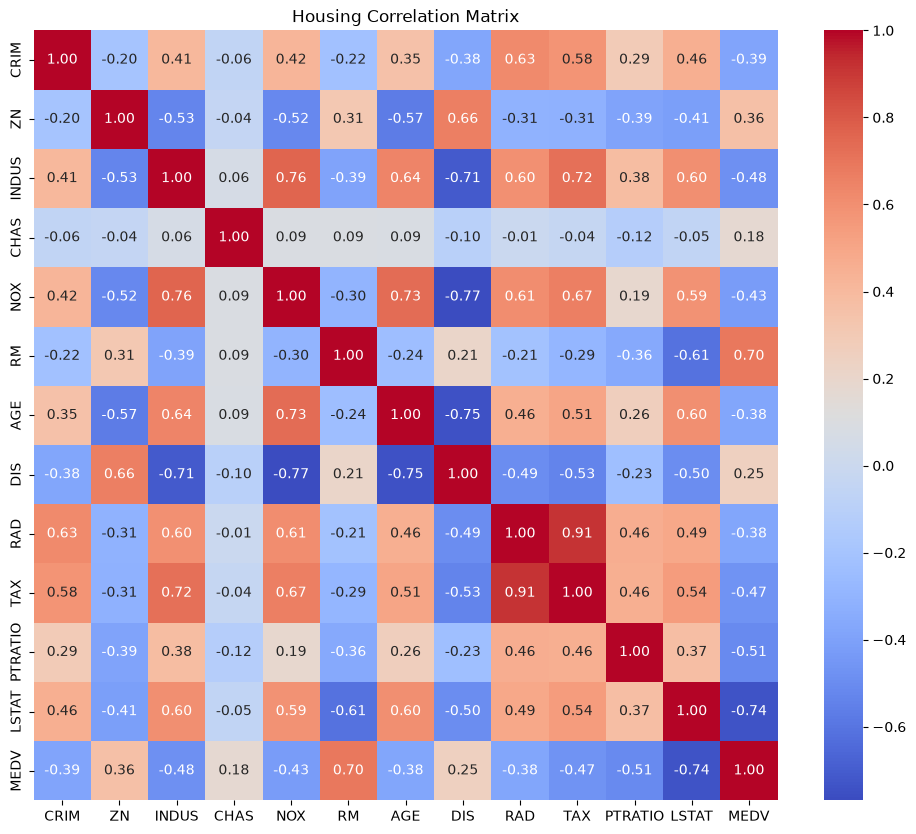

In [55]:
corr_matrix = housing_df.corr()

# Create Heatmap
plt.figure(figsize=(12,10))
sns.heatmap(
  corr_matrix,
  annot=True,
  cmap="coolwarm",
  fmt=".2f"
)

plt.title("Housing Correlation Matrix")

plt.show()

In [56]:
# examine correlation with MEDV

medv_corr = corr_matrix["MEDV"].sort_values(ascending=False)

print(medv_corr)

MEDV       1.000000
RM         0.695360
ZN         0.360445
DIS        0.249929
CHAS       0.175260
AGE       -0.376955
RAD       -0.381626
CRIM      -0.388305
NOX       -0.427321
TAX       -0.468536
INDUS     -0.483725
PTRATIO   -0.507787
LSTAT     -0.737663
Name: MEDV, dtype: float64


# Data Processing

In [57]:
X = housing_df.drop(columns="MEDV") # input features
y = housing_df["MEDV"] # Target

print("X shape: ", X.shape) 
print("y shape: ", y.shape)

X shape:  (506, 12)
y shape:  (506,)


In [58]:
selector = SelectKBest(score_func=f_regression, k='all')
selector.fit(X, y)

scores = pd.DataFrame({
  "Feature": X.columns,
  "Score": selector.scores_
})

print(scores.sort_values(by="Score", ascending=False))

    Feature       Score
11    LSTAT  601.617871
5        RM  471.846740
10  PTRATIO  175.105543
2     INDUS  153.954883
9       TAX  141.761357
4       NOX  112.591480
0      CRIM   89.486115
8       RAD   85.914278
6       AGE   83.477459
1        ZN   75.257642
7       DIS   33.579570
3      CHAS   15.971512


# Train/Test Split

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
  X,
  y,
  random_state=123321
)

print("X_train: ", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train: ", y_train.shape)
print("y_test: ", y_test.shape)

X_train:  (379, 12)
X_test:  (127, 12)
y_train:  (379,)
y_test:  (127,)


# Ridge Regression

In [60]:
ridge_model = Ridge()

ridge_model.fit(X_train, y_train)

#Predictions
y_pred = ridge_model.predict(X_test)

print(y_pred[:5])

[15.45810329 15.24338224 21.92350905 19.0087149  30.74029936]


# Validation

train and test scores

In [61]:
train_score = ridge_model.score(X_train, y_train)
test_score = ridge_model.score(X_test, y_test)

print("Train Score: ", train_score)
print("Test Score: ", test_score)

Train Score:  0.7359040617567901
Test Score:  0.7025862374466145


In [62]:
score_diff = train_score - test_score
print("Difference: ", score_diff)

Difference:  0.0333178243101756


The model seems to be fit well. Difference at around 0.033, suggesting the model shows little evidence of overfitting

In [63]:
#Test alpha =10.0
ridge_alpha = Ridge(alpha=10.0)

ridge_alpha.fit(X_train, y_train)

train_score_alpha = ridge_alpha.score(X_train, y_train)
test_score_alpha = ridge_alpha.score(X_test, y_test)

print("Train Score: ", train_score_alpha)
print("Test Score: ", test_score_alpha)

Train Score:  0.7274038900366313
Test Score:  0.6915899997295487


In [64]:
sgd_model = SGDRegressor(random_state=1233321)

sgd_model.fit(X_train, y_train)

print("Train Score: ", sgd_model.score(X_train, y_train))
print("Test Score: ", sgd_model.score(X_test, y_test))

Train Score:  -8.199767668150788e+25
Test Score:  -1.0956283315546634e+26


# Residual Plot

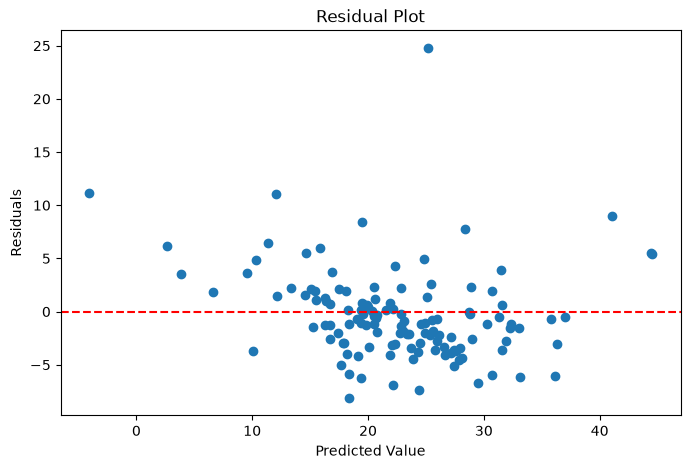

In [65]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Value")
plt.ylabel("Residuals")

plt.show()

 # Calculate estimator metrics

In [66]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("R2: ", r2)
print("Mean Squared Error: ", mse)
print("Mean Absolute Error: ", mae)

R2:  0.7025862374466145
Mean Squared Error:  18.429951050936527
Mean Absolute Error:  3.0633304320069668


# Try Data Scaling

In [67]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

# train ridge model with scaled data
ridge_scaled = Ridge()

ridge_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = ridge_scaled.predict(X_test_scaled)

# Check scaled Model

train_score_scaled = ridge_scaled.score(X_train_scaled, y_train)
test_score_scaled = ridge_scaled.score(X_test_scaled, y_test)

print("Scaled Train Score: ", train_score_scaled)
print("Scaled Test Score: ", test_score_scaled)

Scaled Train Score:  0.7391265972702803
Scaled Test Score:  0.6885824955827027


# Polynomial Features

In [68]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# train ridge model on polyominal features
ridge_poly = Ridge()

ridge_poly.fit(X_train_poly, y_train)

y_pred_poly = ridge_poly.predict(X_test_poly)

# check polynomial scores
train_score_poly = ridge_poly.score(X_train_poly, y_train)
test_score_poly = ridge_poly.score(X_test_poly, y_test)

print("Polynomial Train Score:", train_score_poly)
print("Polynomial Test Score:", test_score_poly)

Polynomial Train Score: 0.9219355056160167
Polynomial Test Score: 0.7948591066234121


In [69]:
print("Original Ridge: ", test_score)
print("Scaled Ridge: ", test_score_scaled)
print("Polynomial Ridge: ", test_score_poly)

Original Ridge:  0.7025862374466145
Scaled Ridge:  0.6885824955827027
Polynomial Ridge:  0.7948591066234121


In [70]:
Trial = 10
end = 200
new = end * Trial
print(new)

2000
